# Exercice (avec indices légers) : Classification Iris avec LDA

Objectif : compléter les `__` pour entraîner un classifieur **LDA** sur Iris (2 variables), puis évaluer le modèle.


In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [54]:
# Rappel utile : vocabulaire des métriques de classification
data = {
    "Anglais": ["Accuracy", "Precision", "Recall"],
    "Bonne traduction": ["Exactitude", "Précision", "Rappel / Sensibilité"],
    "Ce que ça mesure": [
        "Taux global de bonnes réponses",
        "Parmi les positifs prédits, combien sont corrects",
        "Parmi les vrais positifs, combien sont détectés"
    ]
}

pd.DataFrame(data)

,Anglais,Bonne traduction,Ce que ça mesure
0,Accuracy,Exactitude,Taux global de bonnes réponses
1,Precision,Précision,"Parmi les positifs prédits, combien sont corrects"
2,Recall,Rappel / Sensibilité,"Parmi les vrais positifs, combien sont détectés"


In [55]:
# 1) Charger le dataset Iris
iris_data = load_iris()

<details><summary><b>Indice</b></summary>
Une fonction d'importation des données Iris a déjà été importée depuis <code>sklearn.datasets</code>.
</details>

In [56]:
print(iris_data.keys()) # iris_data est organisé en dictionnaire

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [57]:
# 2) Restreindre X aux 2 premières features
X = iris_data['data'][:, :2]  # On ne garde que les 2 premières features
y = iris_data['target']

print("Features utilisées :", iris_data.feature_names[0], "et", iris_data.feature_names[1])
print("Nom des classes    :", iris_data.target_names)

print("X shape :", X.shape)
print("y shape :", y.shape)

Features utilisées : sepal length (cm) et sepal width (cm)
Nom des classes    : ['setosa' 'versicolor' 'virginica']
X shape : (150, 2)
y shape : (150,)


<details><summary><b>Indice</b></summary>
On ne garde que deux colonnes correspondant aux mesures du sépale.
</details>

In [58]:
# 3) Train / test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

<details><summary><b>Indice</b></summary>
On sépare les variables explicatives et la variable cible, puis on fixe une proportion pour le test.
</details>

In [59]:
# 4) Modèle LDA
clf = LinearDiscriminantAnalysis()
clf.fit(X_train, y_train)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None
Name,Type,Value
"classes_ classes_: array-like of shape (n_classes,)Unique class labels.","ndarray[int64](3,)","[0,1,2]"
"coef_ coef_: ndarray of shape (n_features,) or (n_classes, n_features)Weight vector(s).","ndarray[float64](3, 2)","[[-6.04, 8.78], [ 1.35,-3.9 ], [ 3.71,-3.46]]"
"explained_variance_ratio_ explained_variance_ratio_: ndarray of shape (n_components,)Percentage of variance explained by each of the selected components.If ``n_components`` is not set then all components are stored and thesum of explained variances is equal to 1.0. Only available when eigenor svd solver is used.","ndarray[float64](2,)","[0.94,0.06]"


<details><summary><b>Indice</b></summary>
Le modèle utilisé est une méthode d'analyse discriminante linéaire de sklearn.
</details>

In [60]:
# 5) Prédictions
y_pred = clf.predict(X_test)

<details><summary><b>Indice</b></summary>
On applique le modèle appris aux données de test.
</details>

In [61]:
# 6) Matrice de confusion
class_names = iris_data.target_names
cm = confusion_matrix(y_test, y_pred)

print("\nLecture : lignes = vraies classes | colonnes = classes prédites")
pd.DataFrame(cm, index=class_names, columns=class_names)


Lecture : lignes = vraies classes | colonnes = classes prédites


,setosa,versicolor,virginica
setosa,19,0,0
versicolor,0,8,5
virginica,0,2,11


<details><summary><b>Indice</b></summary>
Cette matrice compare les classes réelles aux classes prédites.
</details>

In [62]:
# 7) Exactitude et rapport
# Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"\nAccuracy : {acc:.3f}")

# Rapport de classification
report = classification_report(y_test, y_pred, target_names=class_names)
print("\nRapport de classification :")
print(report)


Accuracy : 0.844

Rapport de classification :
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       0.80      0.62      0.70        13
   virginica       0.69      0.85      0.76        13

    accuracy                           0.84        45
   macro avg       0.83      0.82      0.82        45
weighted avg       0.85      0.84      0.84        45



<details><summary><b>Indice</b></summary>
Ces métriques s'appuient sur la comparaison entre vérité terrain et prédictions.
</details>

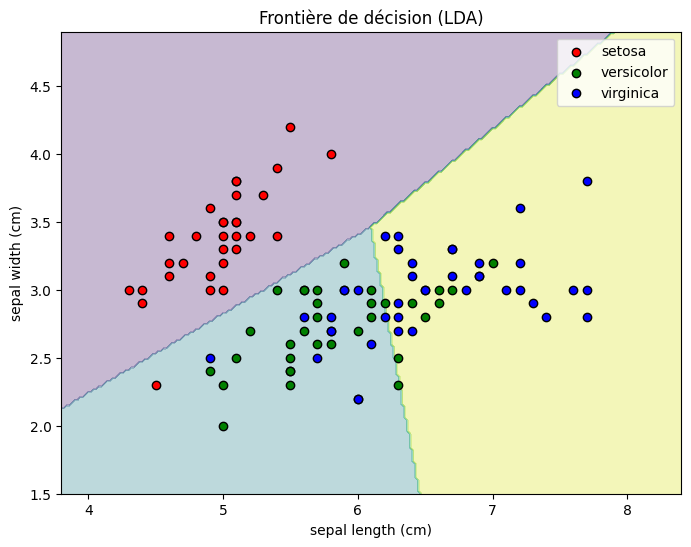

In [63]:
# 8) Visualiser la séparation de l'espace des paramètres (frontière de décision)
# Objectif : afficher les régions de décision du classifieur LDA dans le plan (feature 1, feature 2).

# Grille couvrant l'espace des données
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

# Prédire sur la grille (à compléter)
Z = clf.predict(grid_points)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3)

# Afficher les points d'entraînement
colors = ['red', 'green', 'blue']
for i, color in enumerate(colors):
    plt.scatter(
        X_train[y_train == i, 0], X_train[y_train == i, 1],
        c=color, label=class_names[i], edgecolor='k'
    )

plt.xlabel(iris_data.feature_names[0])
plt.ylabel(iris_data.feature_names[1])
plt.legend()
plt.title("Frontière de décision (LDA)")
plt.show()

<details><summary><b>Indice</b></summary>
On veut prédire la classe pour chaque point de la grille (le tableau <code>grid_points</code>).
</details>